# Drawdown (Underwater) Chart

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Plots, for every date, how far an investment sits below its previous peak. The area hangs "underwater" from a zero line, so the depth, length and frequency of losses become visible. A cumulative-return chart hides these, because recoveries quickly paint over the dips.

## When to use

- Show the pain an investor would have experienced, not just the end result
- Compare maximum drawdown and time-to-recovery between strategies
- Pair with a cumulative-return chart in a performance report

## Avoid when

- The series never falls meaningfully below its peak (the chart is empty)
- Very short histories, where one dip dominates

## Alternatives

- Cumulative return chart with peaks marked
- Table of the five worst drawdowns (depth, start, trough, recovery)

## Design tips

- Share the x-axis with a price panel above; never put drawdown on a second y-axis
- Annotate the maximum drawdown and how long recovery took
- Fill in a single "loss" color; the zero line is the reference

## Example

Simulated daily prices for a fund, 2015–2024, with a sharp 2020-style crash and a slower 2022-style bear market. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.ticker import PercentFormatter, LogLocator, FuncFormatter

### Data

In [2]:
rng = np.random.default_rng(21)
dates = pd.bdate_range("2015-01-01", "2024-12-31")
n = len(dates)
r = 0.00045 + rng.standard_t(4, n) * 0.0095 / np.sqrt(2)
r[(dates >= "2020-02-20") & (dates <= "2020-03-23")] -= 0.012
r[(dates >= "2022-01-01") & (dates <= "2022-10-15")] -= 0.0011
price = pd.Series(100 * np.cumprod(1 + r), index=dates, name="Fund")
price.tail()

2024-12-25    251.465847
2024-12-26    257.600354
2024-12-27    253.262608
2024-12-30    252.750272
2024-12-31    252.037819
Freq: B, Name: Fund, dtype: float64

### Plot

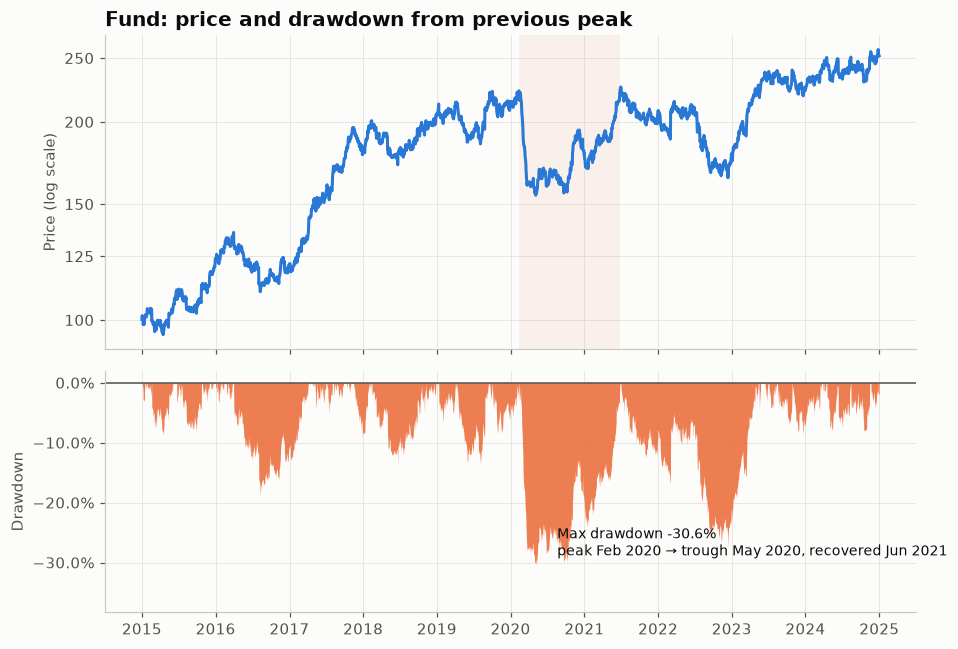

In [3]:
drawdown = price / price.cummax() - 1
trough = drawdown.idxmin()
peak = price.loc[:trough].idxmax()
recovered = price.loc[trough:][price.loc[trough:] >= price.loc[peak]]
recovery = recovered.index[0] if len(recovered) else None

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(price.index, price, color=PALETTE[0])
ax1.set_yscale("log")
ax1.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 1.25, 1.5, 2, 2.5, 3, 4, 5, 7]))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax1.set_ylabel("Price (log scale)")
ax1.set_title(f"{price.name}: price and drawdown from previous peak")
ax1.axvspan(peak, recovery or price.index[-1], color=PALETTE[1], alpha=0.08, linewidth=0)

ax2.fill_between(drawdown.index, drawdown, 0, color=PALETTE[1], alpha=0.85, linewidth=0)
ax2.axhline(0, color="#52514e", linewidth=1)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_ylabel("Drawdown")
rec_text = f"recovered {recovery:%b %Y}" if recovery is not None else "not yet recovered"
ax2.annotate(f"Max drawdown {drawdown.min():.1%}\npeak {peak:%b %Y} → trough {trough:%b %Y}, {rec_text}",
             (trough, drawdown.min()), xytext=(14, 4), textcoords="offset points", fontsize=9,
             va="bottom", color="#0b0b0b")
ax2.set_ylim(drawdown.min() * 1.25, 0.02)
fig.tight_layout()
plt.show()

## How to read it

The top panel is the price on a log scale. The bottom panel shows the percentage below the running peak: zero means a new high. Deep, narrow troughs are crashes; long, shallow ones are slow bleeds that can be just as painful to sit through.

## Try it with real data

**Source:** plotly.express.data.stocks() — weekly NFLX, 2018–2019

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
stocks = px.data.stocks().set_index("date")
price = pd.Series(100 * stocks["NFLX"].values, index=pd.to_datetime(stocks.index), name="NFLX")
price.tail()

date
2019-12-02    146.364112
2019-12-09    142.149623
2019-12-16    160.436205
2019-12-23    156.716981
2019-12-30    154.088290
Name: NFLX, dtype: float64

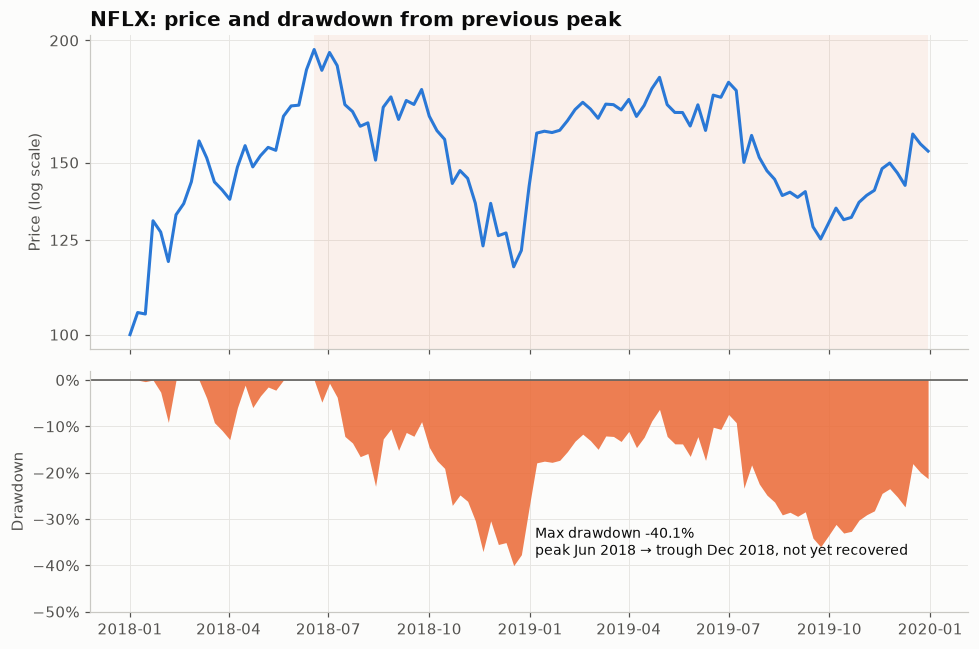

In [5]:
drawdown = price / price.cummax() - 1
trough = drawdown.idxmin()
peak = price.loc[:trough].idxmax()
recovered = price.loc[trough:][price.loc[trough:] >= price.loc[peak]]
recovery = recovered.index[0] if len(recovered) else None

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(price.index, price, color=PALETTE[0])
ax1.set_yscale("log")
ax1.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 1.25, 1.5, 2, 2.5, 3, 4, 5, 7]))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax1.set_ylabel("Price (log scale)")
ax1.set_title(f"{price.name}: price and drawdown from previous peak")
ax1.axvspan(peak, recovery or price.index[-1], color=PALETTE[1], alpha=0.08, linewidth=0)

ax2.fill_between(drawdown.index, drawdown, 0, color=PALETTE[1], alpha=0.85, linewidth=0)
ax2.axhline(0, color="#52514e", linewidth=1)
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.set_ylabel("Drawdown")
rec_text = f"recovered {recovery:%b %Y}" if recovery is not None else "not yet recovered"
ax2.annotate(f"Max drawdown {drawdown.min():.1%}\npeak {peak:%b %Y} → trough {trough:%b %Y}, {rec_text}",
             (trough, drawdown.min()), xytext=(14, 4), textcoords="offset points", fontsize=9,
             va="bottom", color="#0b0b0b")
ax2.set_ylim(drawdown.min() * 1.25, 0.02)
fig.tight_layout()
plt.show()

---
Standalone script: [`drawdown_underwater.py`](drawdown_underwater.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)